# Series de tiempo 0 — Introducción y obtención de datos
**Versión comentada y ampliada del cuaderno original.**

## Objetivos
- Reconocer una serie temporal y su índice de fechas.
- Descargar y visualizar precios financieros con `yfinance`.
- Transformar datos históricos de COVID-19 desde formato ancho a una serie diaria.
- Consultar la TRM desde la API pública de datos.gov.co.

Este cuaderno es **exploratorio**: todavía no ajusta modelos de pronóstico. Los ejemplos dependen de fuentes externas, cuya disponibilidad puede cambiar.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True

## 1. ¿Qué es una serie de tiempo?
Una serie temporal es una sucesión de observaciones \(X_t\) asociadas a instantes o períodos ordenados. Importan tanto los valores como **cuándo** se midieron.

Conviene distinguir **frecuencia** (diaria, mensual, etc.), **observaciones faltantes**, **intervalos irregulares**, **valor observado** y **valor imputado**. Una cotización ausente durante un cierre bursátil no equivale a un precio igual a cero.

`DatetimeIndex` permite conservar el calendario y seleccionar intervalos de fechas.

In [3]:
import yfinance as yf
def obtener_cierre(simbolo, inicio, fin):
    s = yf.Ticker(simbolo).history(start=inicio, end=fin)["Close"].copy()
    if s.empty:
        print(f"Sin cotizaciones: {simbolo}")
        return pd.Series(dtype=float, name=simbolo)
    s.index = pd.to_datetime(s.index).tz_localize(None).normalize()
    s = s.sort_index()
    s.name = simbolo
    return s

## 2. Cotizaciones: Bitcoin, Ecopetrol y Microsoft
Reproducimos los tres activos del cuaderno original: `BTC-USD`, `EC` y `MSFT`. Bitcoin suele cotizar todos los días; las acciones siguen calendarios bursátiles. Por ello no esperamos que sus índices tengan las mismas fechas.

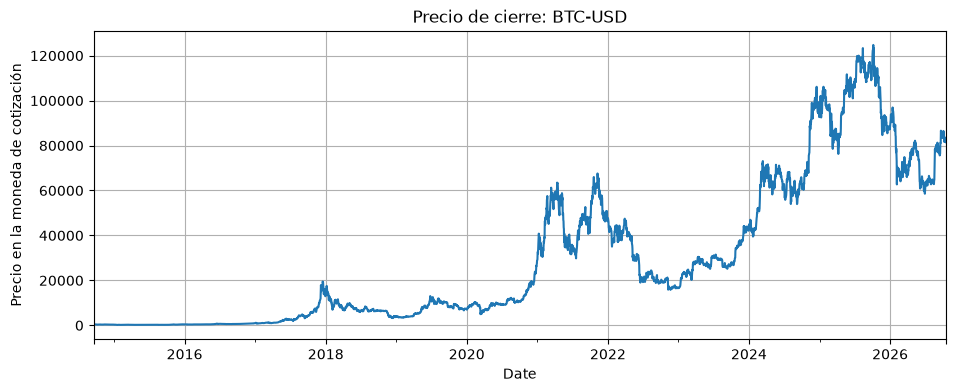

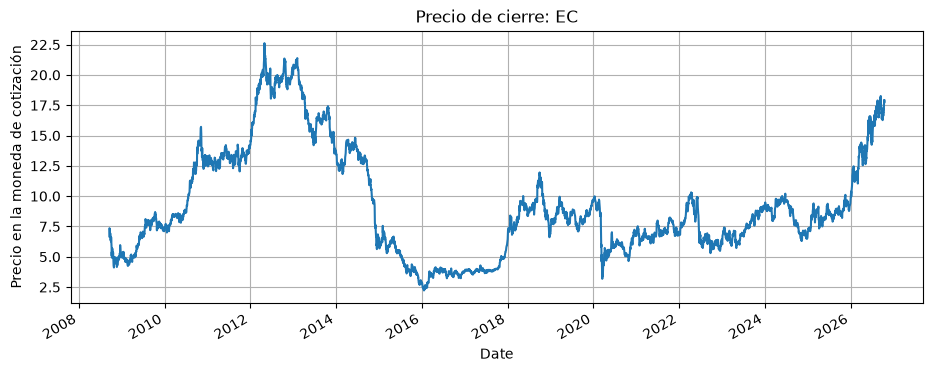

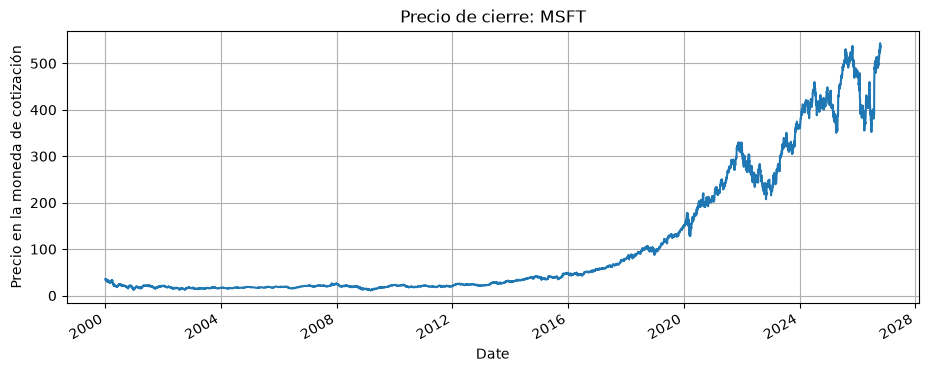

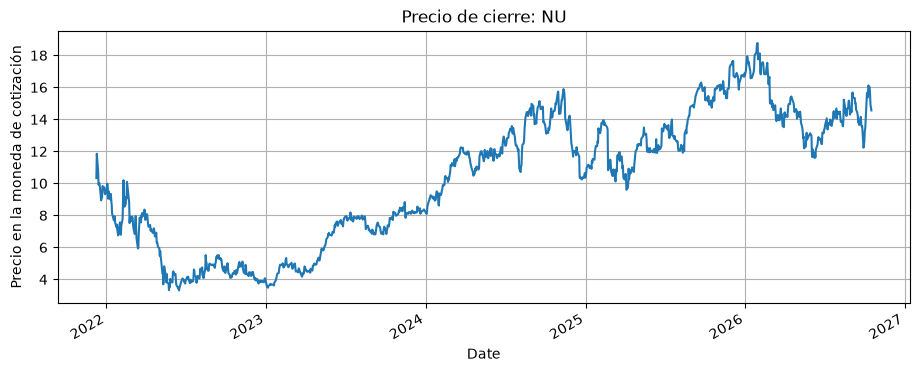

In [4]:
inicio, fin = "2000-01-01", "2026-10-19"
activos = {}
for simbolo in ["BTC-USD", "EC", "MSFT","NU"]:
    activos[simbolo] = obtener_cierre(simbolo, inicio, fin)
    if not activos[simbolo].empty:
        activos[simbolo].plot(title=f"Precio de cierre: {simbolo}")
        plt.ylabel("Precio en la moneda de cotización")
        plt.show()

In [7]:
activos['BTC-USD'].info()

<class 'pandas.Series'>
DatetimeIndex: 4415 entries, 2014-09-17 to 2026-10-18
Freq: D
Series name: BTC-USD
Non-Null Count  Dtype  
--------------  -----  
4415 non-null   float64
dtypes: float64(1)
memory usage: 69.0 KB


**Interpretación.** Comparar niveles de precios entre activos diferentes no equivale a comparar rentabilidades. Tampoco debe inferirse una periodicidad semanal de la presencia de días de la semana en el calendario.

### Pregunta
¿Cuántas observaciones tiene cada activo y cuál es la distancia en días entre observaciones consecutivas?

In [8]:
for nombre, s in activos.items():
    if len(s)>1:
        saltos = s.index.to_series().diff().dt.days.value_counts().sort_index()
        print(nombre, "observaciones:",len(s))
        display(saltos.rename("frecuencia de saltos (días)").to_frame())

BTC-USD observaciones: 4415


,frecuencia de saltos (días)
Date,
1.0,4414


EC observaciones: 4548


,frecuencia de saltos (días)
Date,
1.0,3559
2.0,45
3.0,820
4.0,122
5.0,1


MSFT observaciones: 6738


,frecuencia de saltos (días)
Date,
1.0,5274
2.0,66
3.0,1216
4.0,178
5.0,2
7.0,1


NU observaciones: 1218


,frecuencia de saltos (días)
Date,
1.0,951
2.0,13
3.0,217
4.0,36


## 3. Casos COVID-19: de tabla ancha a serie temporal
El archivo de Johns Hopkins contiene columnas de fechas y filas por país/provincia. El cuaderno original transponía el archivo y reasignaba encabezados. Aquí hacemos la misma transformación con agrupación explícita por país, para evitar columnas duplicadas cuando existen varias provincias.

Los valores son **casos confirmados acumulados**. Para estimar los casos nuevos reportados cada día calculamos:

$$
N_t=C_t-C_{t-1}.
$$

La primera diferencia no está definida: se conserva como `NaN` hasta descartarla. Las correcciones históricas pueden producir diferencias negativas.

In [11]:
url_covid = ("https://raw.githubusercontent.com/CSSEGISandData/COVID-19/"
 "master/csse_covid_19_data/csse_covid_19_time_series/"
 "time_series_covid19_confirmed_global.csv")
covid_raw = pd.read_csv(url_covid)
#covid_raw
columnas_fechas = covid_raw.columns[4:]
covid_paises = covid_raw.groupby("Country/Region")[columnas_fechas].sum().T
covid_paises.index = pd.to_datetime(covid_paises.index, format="%m/%d/%y")
covid_paises = covid_paises.sort_index()
display(covid_paises.iloc[:5, :5])

Country/Region,Afghanistan,Albania,Algeria,Andorra,Angola
2020-01-22,0,0,0,0,0
2020-01-23,0,0,0,0,0
2020-01-24,0,0,0,0,0
2020-01-25,0,0,0,0,0
2020-01-26,0,0,0,0,0


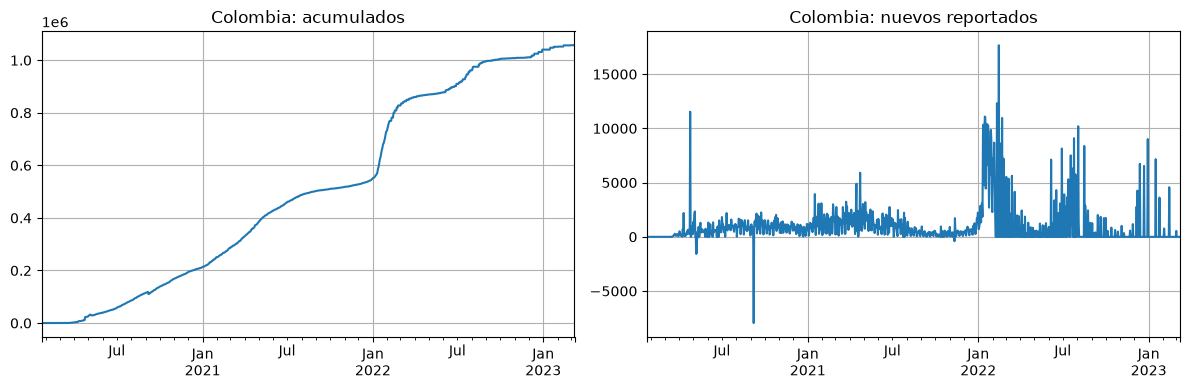

Diferencias negativas: 5


In [13]:
colombia_acum = covid_paises["Ecuador"].rename("Casos acumulados")
colombia_diarios = colombia_acum.diff().dropna().rename("Casos diarios reportados")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
colombia_acum.plot(ax=ax[0], title="Colombia: acumulados")
colombia_diarios.plot(ax=ax[1], title="Colombia: nuevos reportados")
plt.tight_layout()
plt.show()
print("Diferencias negativas:", (colombia_diarios<0).sum())

## 4. API pública: TRM colombiana
El cuaderno original utilizaba Socrata y el conjunto `mcec-87by`. Conservamos esa fuente, pero **no suponemos que el orden de las columnas de la respuesta sea fijo**. Primero inspeccionamos sus nombres y después convertimos fechas y valores.

In [14]:
from sodapy import Socrata
# Dataset utilizado en el cuaderno original. La disponibilidad y el esquema
# dependen del portal datos.gov.co.
with Socrata("www.datos.gov.co", None) as client:
    registros = client.get("mcec-87by", limit=10000)
trm_raw = pd.DataFrame.from_records(registros)
print("Columnas originales:", list(trm_raw.columns))
display(trm_raw.head())

Columnas originales: ['valor', 'unidad', 'vigenciadesde', 'vigenciahasta']


,valor,unidad,vigenciadesde,vigenciahasta
0,3156.32,COP,2026-10-20T00:00:00.000,2026-10-20T00:00:00.000
1,3174.67,COP,2026-10-17T00:00:00.000,2026-10-19T00:00:00.000
2,3170.46,COP,2026-10-16T00:00:00.000,2026-10-16T00:00:00.000
3,3197.65,COP,2026-10-15T00:00:00.000,2026-10-15T00:00:00.000
4,3181.74,COP,2026-10-14T00:00:00.000,2026-10-14T00:00:00.000


In [15]:
# Se conservan nombres originales: NO se renombran por posición.
candidatas_fecha = [c for c in trm_raw if "asta" in c.lower()]
candidatas_valor = [c for c in trm_raw if ("alor" in c.lower() or "trm" in c.lower())]
print("Posibles fechas:", candidatas_fecha)
print("Posibles valores:", candidatas_valor)
#if not candidatas_fecha or not candidatas_valor:
#    raise ValueError("Revisar columnas devueltas por la API antes de continuar")
fecha_col = candidatas_fecha[0]
valor_col = candidatas_valor[0]
trm = trm_raw[[fecha_col, valor_col]].copy()
trm[fecha_col] = pd.to_datetime(trm[fecha_col], errors="coerce", utc=True).dt.tz_localize(None).dt.normalize()
trm[valor_col] = pd.to_numeric(trm[valor_col], errors="coerce")
trm = (trm.dropna().sort_values(fecha_col)
       .drop_duplicates(fecha_col, keep="last")
       .set_index(fecha_col)[valor_col].rename("TRM"))
display(trm.head())
print("Rango:", trm.index.min(), trm.index.max())

Posibles fechas: ['vigenciahasta']
Posibles valores: ['valor']


vigenciahasta
1991-12-02    643.42
1991-12-03    639.22
1991-12-04    635.70
1991-12-05    631.51
1991-12-06    627.16
Name: TRM, dtype: float64

Rango: 1991-12-02 00:00:00 2026-10-20 00:00:00


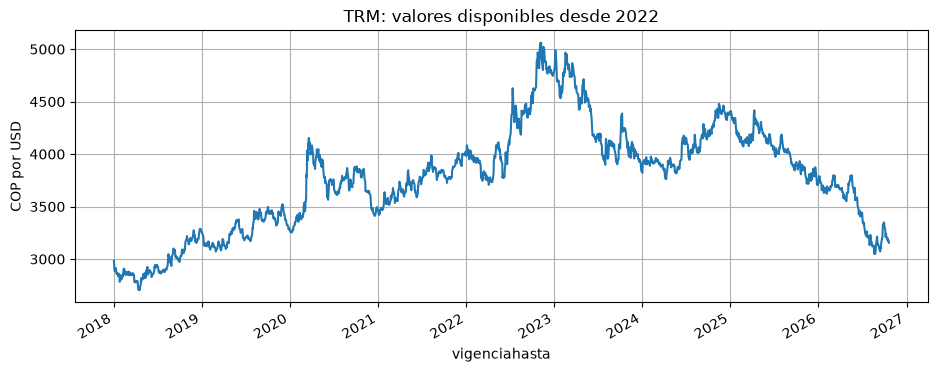

Duplicados en fecha: 0


In [16]:
trm.loc["2018-01-01":].plot(title="TRM: valores disponibles desde 2022")
plt.ylabel("COP por USD")
plt.show()
print("Duplicados en fecha:",trm.index.duplicated().sum())

## 5. Síntesis
En este cuaderno aprendimos a recuperar, convertir y visualizar datos. Antes de cualquier pronóstico es necesario verificar: unidad, calendario, valores faltantes, revisiones, duplicados y significado de las fechas.

**Actividades:** (1) comparar el número de sesiones de Microsoft y días de Bitcoin; (2) explicar por qué `diff()` genera un faltante inicial; (3) investigar si la TRM representa un precio negociado o una tasa de referencia publicada.

**Siguiente cuaderno:** concatenación, alineación de índices, frecuencia diaria e imputación.

In [30]:
# Base de datos de salida de colombianos hacia el exterior, mensual y por pais
import pandas as pd
from sodapy import Socrata

client = Socrata("www.datos.gov.co", None)
results = client.get("efw5-jiej", limit=94000)

results_df = pd.DataFrame.from_records(results)
results_df

,a_o,mes,pa_s_destino,codigo_m49,femenino,masculino,total,ubicacion_pcm
0,2012,Enero,Afganistán,4,0,1,1,"(10.886611,-74.776708)"
1,2012,Enero,Afganistán,4,1,20,21,"(4.697144,-74.140516)"
2,2012,Enero,Alemania,276,1,0,1,"(0.814836,-77.662532)"
3,2012,Enero,Alemania,276,5,2,7,"(10.445761,-75.516429)"
4,2012,Enero,Alemania,276,3,2,5,"(10.886611,-74.776708)"
...,...,...,...,...,...,...,...,...
93012,2026,Junio,Venezuela (República Bolivariana De),862,118,150,268,"(8.36068,-72.409396)"
93013,2026,Junio,Venezuela (República Bolivariana De),862,670,774,1444,"(8.364293,-72.405710)"
93014,2026,Junio,Viet Nam,704,2,1,3,"(3.541112,-76.384584)"
93015,2026,Junio,Viet Nam,704,2,1,3,"(4.697144,-74.140516)"


In [44]:
df=results_df.copy()
df['mes']=df['mes'].map({'Enero': 1, 'Febrero': 2, 'Marzo': 3, 'Abril': 4, 'Mayo': 5, 'Junio': 6, 'Julio': 7, 'Agosto': 8, 'Septiembre': 9, 'Octubre': 10, 'Noviembre': 11, 'Diciembre': 12})
df['dia']=1
df['fecha'] = pd.to_datetime(
    df.rename(columns={'a_o': 'year', 'mes': 'month', 'dia': 'day'})[
        ['year', 'month', 'day']
    ]
)
df.set_index('fecha', inplace=True)
df=df[['pa_s_destino','femenino','masculino','total']]
df['total']=pd.to_numeric(df['total'], errors='coerce')
df['pa_s_destino']=df['pa_s_destino'].str.upper()
df2=pd.pivot_table(df, index=df.index, columns='pa_s_destino', values='total', aggfunc='sum').fillna(0)
df2

pa_s_destino,AFGANISTÁN,ALBANIA,ALEMANIA,ANDORRA,ANGOLA,ANGUILA,ANTIGUA Y BARBUDA,ANTÁRTIDA,ARABIA SAUDITA,ARGELIA,...,UGANDA,URUGUAY,UZBEKISTÁN,VANUATU,VENEZUELA (REPÚBLICA BOLIVARIANA DE),VIET NAM,YEMEN,YUGOSLAVIA,ZAMBIA,ZIMBABWE
fecha,,,,,,,,,,,,,,,,,,,,,
2012-01-01,22.0,0.0,1812.0,1.0,28.0,0.0,9.0,0.0,83.0,24.0,...,2.0,174.0,0.0,1.0,52983.0,3.0,1.0,1.0,1.0,0.0
2012-02-01,17.0,2.0,1288.0,3.0,9.0,0.0,2.0,0.0,19.0,16.0,...,0.0,166.0,0.0,1.0,27816.0,2.0,0.0,0.0,0.0,0.0
2012-03-01,32.0,0.0,1882.0,0.0,11.0,0.0,0.0,0.0,38.0,18.0,...,1.0,228.0,0.0,0.0,31846.0,4.0,0.0,0.0,2.0,1.0
2012-04-01,31.0,0.0,1727.0,5.0,14.0,0.0,0.0,0.0,26.0,9.0,...,0.0,139.0,0.0,0.0,34255.0,2.0,0.0,0.0,0.0,0.0
2012-05-01,30.0,3.0,2256.0,3.0,16.0,0.0,0.0,0.0,37.0,9.0,...,2.0,174.0,0.0,0.0,30375.0,6.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-02-01,5.0,8.0,1818.0,9.0,1.0,6.0,2.0,0.0,10.0,1.0,...,0.0,901.0,3.0,0.0,6741.0,5.0,1.0,0.0,0.0,0.0
2026-03-01,1.0,7.0,2155.0,9.0,0.0,13.0,3.0,0.0,13.0,2.0,...,0.0,1031.0,0.0,0.0,10130.0,6.0,0.0,0.0,1.0,0.0
2026-04-01,1.0,4.0,2041.0,12.0,1.0,0.0,1.0,0.0,13.0,6.0,...,0.0,672.0,4.0,0.0,9496.0,4.0,0.0,0.0,3.0,0.0


In [48]:
[c for c in df2.columns]

['AFGANISTÁN',
 'ALBANIA',
 'ALEMANIA',
 'ANDORRA',
 'ANGOLA',
 'ANGUILA',
 'ANTIGUA Y BARBUDA',
 'ANTÁRTIDA',
 'ARABIA SAUDITA',
 'ARGELIA',
 'ARGENTINA',
 'ARMENIA',
 'ARUBA',
 'AUSTRALIA',
 'AUSTRIA',
 'AZERBAIYÁN',
 'BAHAMAS',
 'BAHREIN',
 'BANGLADESH',
 'BARBADOS',
 'BELARÚS',
 'BELICE',
 'BENIN',
 'BERMUDA',
 'BOLIVIA (ESTADO PLURINACIONAL DE)',
 'BONAIRE, SAN EUSTAQUIO Y SABA',
 'BOSNIA Y HERZEGOVINA',
 'BOTSWANA',
 'BRASIL',
 'BRUNEI DARUSSALAM',
 'BULGARIA',
 'BURKINA FASO',
 'BURUNDI',
 'BUTÁN',
 'BÉLGICA',
 'CABO VERDE',
 'CAMBOYA',
 'CAMERÚN',
 'CANADÁ',
 'CHAD',
 'CHILE',
 'CHINA',
 'CHIPRE',
 'COLOMBIA',
 'COMORAS',
 'CONGO',
 'COSTA DE MARFIL',
 'COSTA RICA',
 'CROACIA',
 'CUBA',
 'CURAZAO',
 'DESCONOCIDO',
 'DINAMARCA',
 'DJIBOUTI',
 'DOMINICA',
 'ECUADOR',
 'EGIPTO',
 'EL SALVADOR',
 'EMIRATOS ÁRABES UNIDOS',
 'ERITREA',
 'ESLOVAQUIA',
 'ESLOVENIA',
 'ESPAÑA',
 'ESTADO DE PALESTINA',
 'ESTADOS UNIDOS DE AMÉRICA',
 'ESTONIA',
 'ESWATINI',
 'ETIOPÍA',
 'FEDERACIÓN DE RUS

<Axes: title={'center': 'Salida de colombianos hacia Estados Unidos'}, xlabel='fecha'>

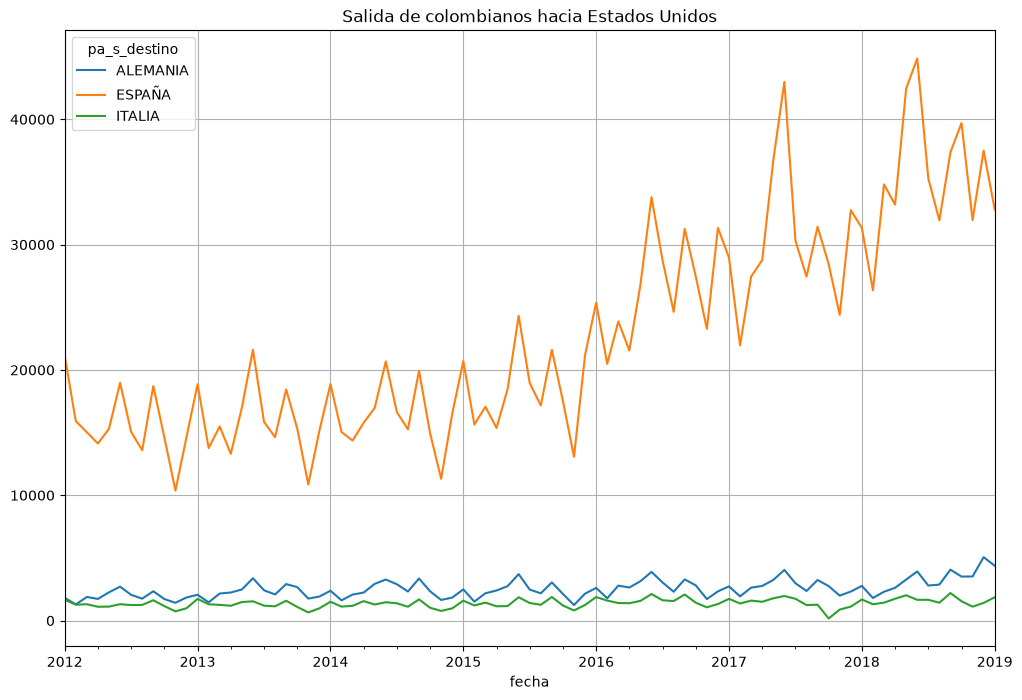

In [53]:
plt.rcParams["figure.figsize"] = (12, 8)
plt.rcParams["axes.grid"] = True
df2[[ 'ALEMANIA','ESPAÑA','ITALIA']].loc[:"2019-01-01"].plot(title="Salida de colombianos hacia Estados Unidos")

In [58]:
cad='2026ene01'
ano=cad[0:4]
mes=cad[4:7]
dia=cad[7:9]
mes=mes.replace('ene','01').replace('feb','02').replace('mar','03').replace('abr','04').replace('may','05').replace('jun','06').replace('jul','07').replace('ago','08').replace('sep','09').replace('oct','10').replace('nov','11').replace('dic','12')
ano, mes, dia
pd.to_datetime(ano+'/'+mes+'/'+dia, format='%Y/%m/%d')

Timestamp('2026-01-01 00:00:00')